# MCS Sweep Analysis — Platoon NR-SL

Reads `results_mcs_sweep/tidy/` (produced by `extract_mcs_sweep.py`) and the
MCS=14 baseline merged within it, then produces:

- §1 Setup
- §2 PRR vs MCS (all scenarios)
- §3 PRR vs distance per MCS
- §4 Worst-RX PRR (per scenario × MCS)
- §5 ΔPRR vs baseline (MCS=14)
- §6 HARQ NACK & PHY error rates
- §7 SINR CDF per MCS
- §8 Per-RX heatmap (rx_node_id × MCS)
- §9 Summary table & recommendation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})

TIDY = Path('results_mcs_sweep/tidy')

MCS_PALETTE = {4:'#1f77b4', 7:'#ff7f0e', 10:'#2ca02c',
               12:'#d62728', 14:'#9467bd', 20:'#8c564b'}
SCENARIO_LABELS = {
    'shadowing_blockage':   'Shadow+Blockage',
    'high_density':         'High Density',
    'variable_packet_size': 'Variable Pkt Size',
}

def slabel(s): return SCENARIO_LABELS.get(s, s)
def mcs_color(m): return MCS_PALETTE.get(int(m), 'grey')

In [2]:
# Load tidy CSVs
df_prx  = pd.read_csv(TIDY / 'per_rx_kpis.csv')
df_comp = pd.read_csv(TIDY / 'mcs_comparison.csv')
df_harq = pd.read_csv(TIDY / 'harq_stats.csv')
df_sinr = pd.read_csv(TIDY / 'sinr_per_rx.csv') if (TIDY/'sinr_per_rx.csv').is_file() else pd.DataFrame()

print(f"per_rx_kpis : {len(df_prx):,} rows")
print(f"mcs_comparison: {len(df_comp):,} rows")
print(f"harq_stats  : {len(df_harq):,} rows")
print(f"sinr_per_rx : {len(df_sinr):,} rows")
print("\nMCS values:", sorted(df_prx['mcs'].unique()))
print("Scenarios :", sorted(df_prx['scenario'].unique()))
print("Seeds     :", df_prx['seed'].nunique(), "unique")

per_rx_kpis : 1,890 rows
mcs_comparison: 15 rows
harq_stats  : 210 rows
sinr_per_rx : 1,845 rows

MCS values: [np.int64(7), np.int64(10), np.int64(12), np.int64(14), np.int64(20)]
Scenarios : ['high_density', 'shadowing_blockage', 'variable_packet_size']
Seeds     : 30 unique


## §2 PRR vs MCS (mean ± 95% CI)

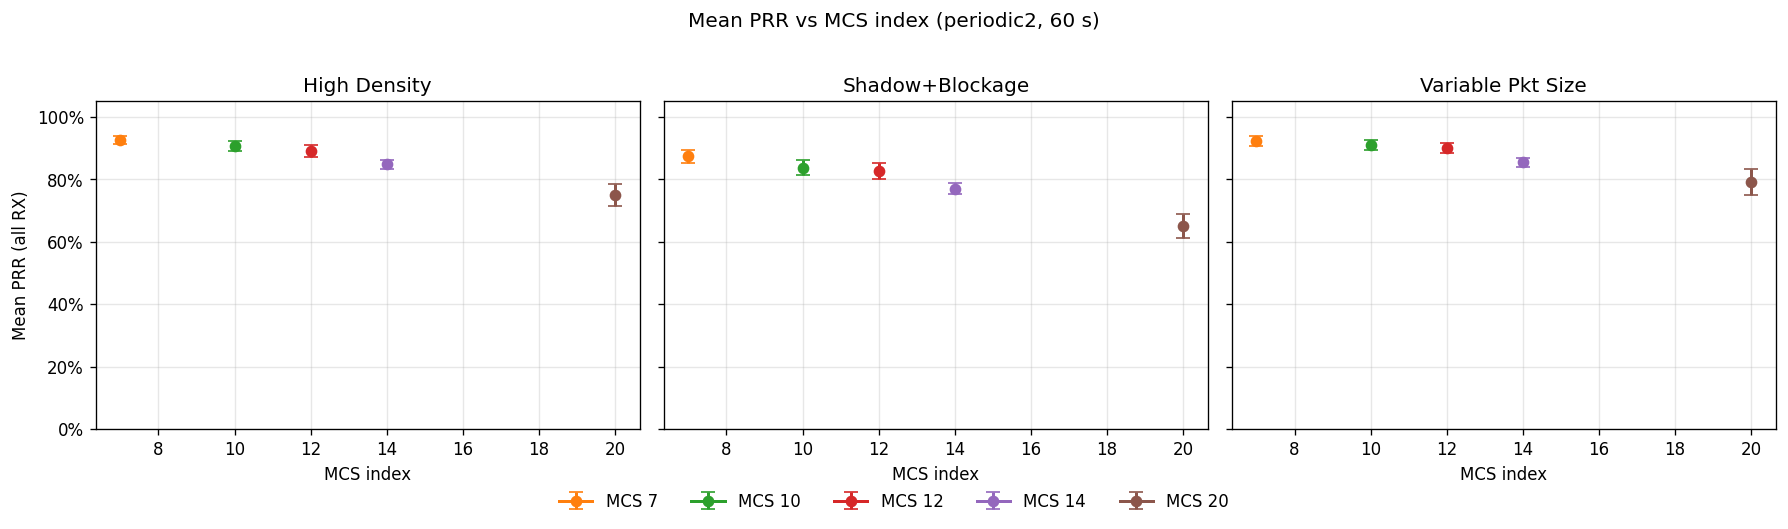

In [3]:
rx = df_prx[df_prx['rx_node_id'] != 0].copy()
scenarios = sorted(rx['scenario'].unique())
mcs_vals = sorted(rx['mcs'].unique())

fig, axes = plt.subplots(1, len(scenarios), figsize=(5*len(scenarios), 4), sharey=True)
if len(scenarios)==1: axes=[axes]

for ax, scen in zip(axes, scenarios):
    sub = rx[rx['scenario']==scen]
    g = sub.groupby('mcs')['prr'].agg(['mean','std','count']).reset_index()
    g['ci95'] = 1.96 * g['std'] / np.sqrt(g['count'].clip(lower=1))
    for _, row in g.sort_values('mcs').iterrows():
        ax.errorbar(row['mcs'], row['mean'], yerr=row['ci95'],
                    fmt='o-', color=mcs_color(row['mcs']),
                    capsize=4, linewidth=1.8, label=f"MCS {int(row['mcs'])}")
    ax.set_title(slabel(scen))
    ax.set_xlabel('MCS index')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax.set_ylim(0, 1.05); ax.grid(True, alpha=.3)
    if ax is axes[0]: ax.set_ylabel('Mean PRR (all RX)')

h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=len(h), bbox_to_anchor=(.5,-.05), frameon=False)
fig.suptitle('Mean PRR vs MCS index (periodic2, 60 s)', y=1.02)
plt.tight_layout()
plt.show()

## §3 PRR vs distance per MCS

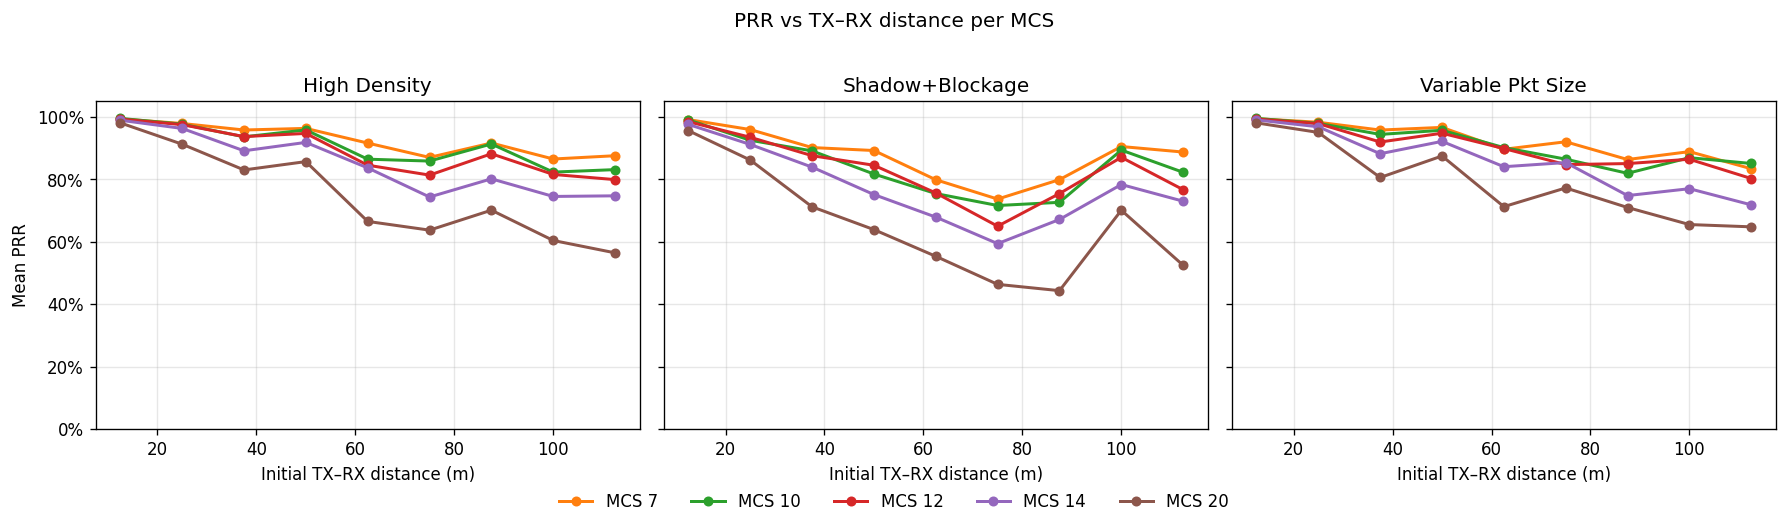

In [4]:
fig, axes = plt.subplots(1, len(scenarios), figsize=(5*len(scenarios), 4), sharey=True)
if len(scenarios)==1: axes=[axes]

for ax, scen in zip(axes, scenarios):
    sub = rx[rx['scenario']==scen]
    for mcs in mcs_vals:
        m = sub[sub['mcs']==mcs].groupby('init_dist_m')['prr'].mean().reset_index()
        if m.empty: continue
        ax.plot(m['init_dist_m'], m['prr'], 'o-',
                color=mcs_color(mcs), label=f'MCS {mcs}', lw=1.8, ms=5)
    ax.set_title(slabel(scen))
    ax.set_xlabel('Initial TX–RX distance (m)')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax.set_ylim(0, 1.05); ax.grid(True, alpha=.3)
    if ax is axes[0]: ax.set_ylabel('Mean PRR')

h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=len(h), bbox_to_anchor=(.5,-.05), frameon=False)
fig.suptitle('PRR vs TX–RX distance per MCS', y=1.02)
plt.tight_layout()
plt.show()

## §4 Worst-RX PRR per (scenario, MCS)

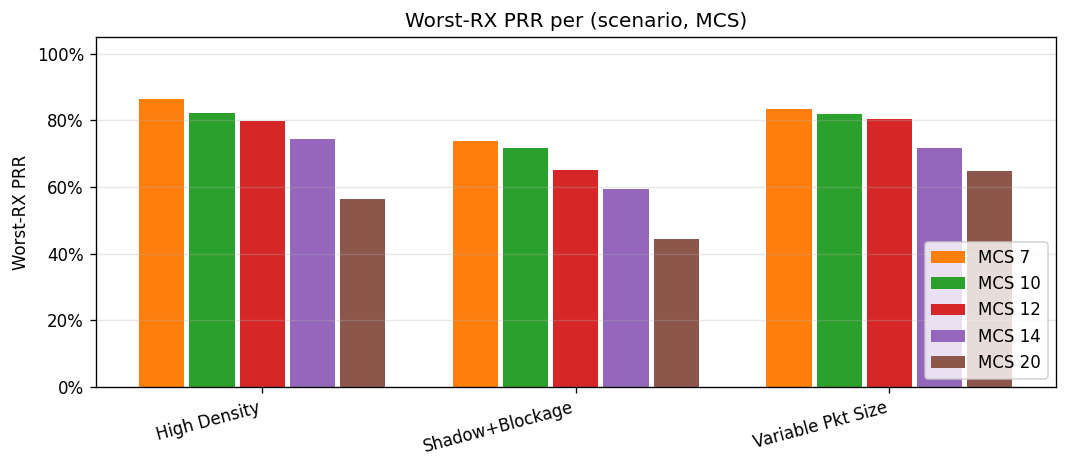


Worst-RX PRR table:
scenario  high_density  shadowing_blockage  variable_packet_size
mcs                                                             
7                0.865               0.737                 0.834
10               0.823               0.716                 0.819
12               0.799               0.650                 0.803
14               0.743               0.594                 0.718
20               0.564               0.443                 0.648


In [5]:
worst = (rx.groupby(['scenario','mcs','rx_node_id'])['prr'].mean()
           .reset_index()
           .groupby(['scenario','mcs'])['prr'].min()
           .reset_index()
           .rename(columns={'prr':'worst_rx_prr'}))

x = np.arange(len(scenarios))
width = 0.8 / len(mcs_vals)
fig, ax = plt.subplots(figsize=(max(6, 3*len(scenarios)), 4))
for i, mcs in enumerate(mcs_vals):
    sub = worst[worst['mcs']==mcs]
    vals = [sub[sub['scenario']==s]['worst_rx_prr'].values[0]
            if len(sub[sub['scenario']==s]) else 0 for s in scenarios]
    offset = x + i*width - (len(mcs_vals)-1)*width/2
    ax.bar(offset, vals, width*0.9, color=mcs_color(mcs), label=f'MCS {mcs}')

ax.set_xticks(x)
ax.set_xticklabels([slabel(s) for s in scenarios], rotation=15, ha='right')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_ylim(0,1.05); ax.set_ylabel('Worst-RX PRR')
ax.set_title('Worst-RX PRR per (scenario, MCS)')
ax.legend(loc='lower right'); ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.show()

print('\nWorst-RX PRR table:')
print(worst.pivot(index='mcs', columns='scenario', values='worst_rx_prr').to_string(float_format=lambda x: f'{x:.3f}'))

## §5 ΔPRR vs MCS=14 baseline

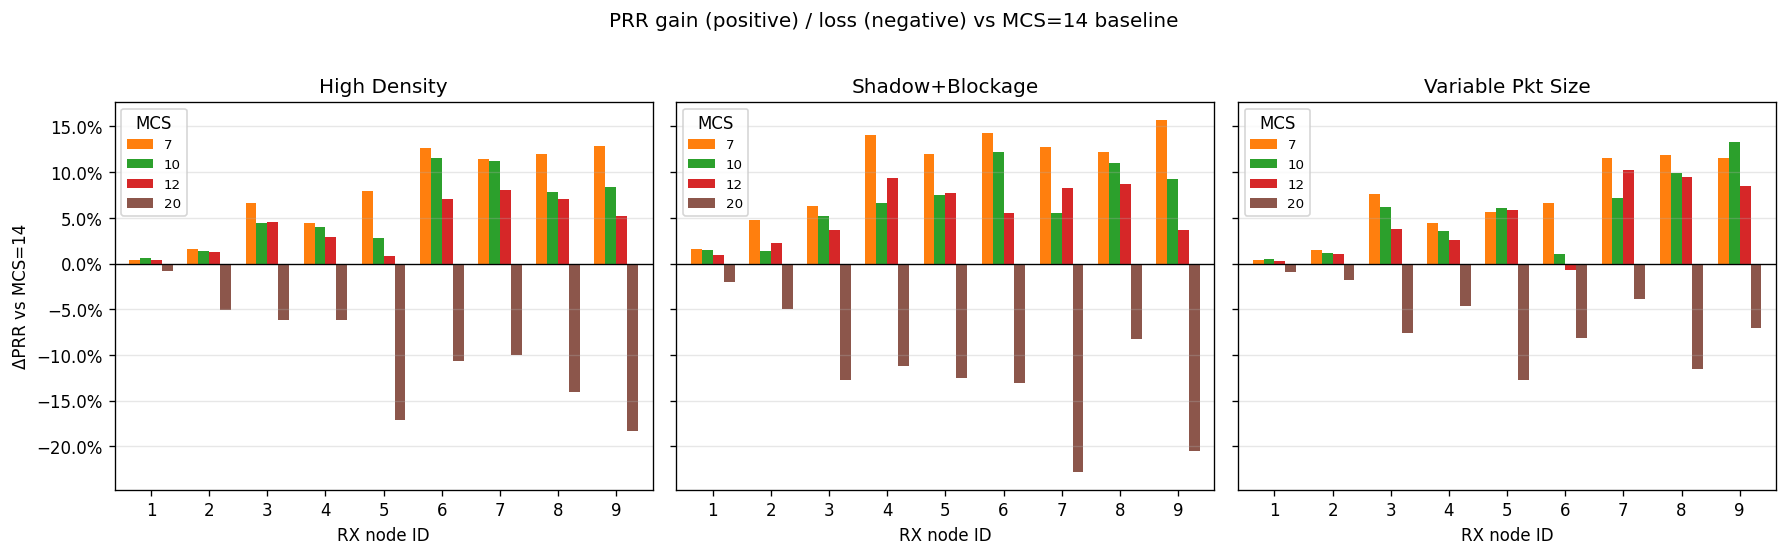

In [6]:
base14 = (rx[rx['mcs']==14]
          .groupby(['scenario','rx_node_id'])['prr'].mean()
          .rename('prr14'))
grp = (rx.groupby(['scenario','mcs','rx_node_id'])['prr'].mean().reset_index())
grp = grp.merge(base14.reset_index(), on=['scenario','rx_node_id'], how='left')
grp['delta'] = grp['prr'] - grp['prr14']
grp = grp[grp['mcs'] != 14]
other_mcs = [m for m in mcs_vals if m!=14]

fig, axes = plt.subplots(1, len(scenarios), figsize=(5*len(scenarios), 4.5), sharey=True)
if len(scenarios)==1: axes=[axes]

for ax, scen in zip(axes, scenarios):
    sub = grp[grp['scenario']==scen]
    pivot = sub.groupby(['rx_node_id','mcs'])['delta'].mean().unstack('mcs')
    cols = [m for m in other_mcs if m in pivot.columns]
    pivot[cols].plot(kind='bar', ax=ax,
                     color=[mcs_color(m) for m in cols], width=0.75)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(slabel(scen))
    ax.set_xlabel('RX node ID')
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
    ax.tick_params(axis='x', rotation=0)
    ax.legend(title='MCS', fontsize=8)
    ax.grid(axis='y', alpha=.3)
    if ax is axes[0]: ax.set_ylabel('ΔPRR vs MCS=14')

fig.suptitle('PRR gain (positive) / loss (negative) vs MCS=14 baseline', y=1.02)
plt.tight_layout()
plt.show()

## §6 HARQ NACK rate vs MCS

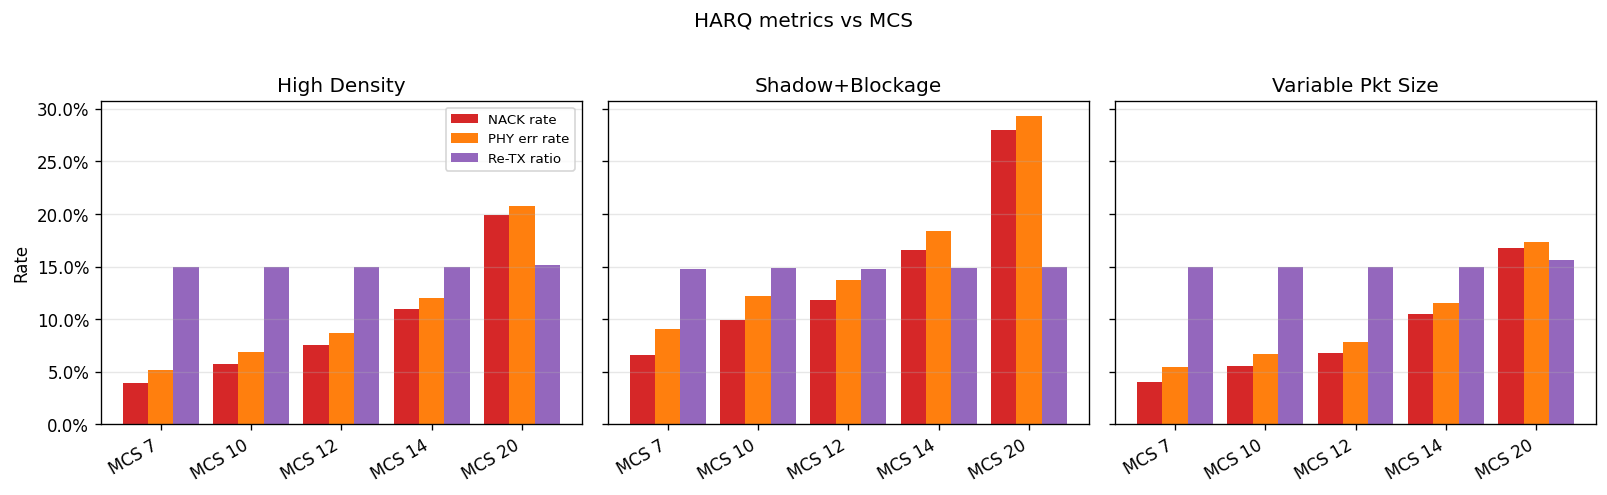

In [7]:
if not df_harq.empty:
    fig, axes = plt.subplots(1, len(scenarios), figsize=(4.5*len(scenarios), 4), sharey=True)
    if len(scenarios)==1: axes=[axes]
    for ax, scen in zip(axes, scenarios):
        sub = df_harq[df_harq['scenario']==scen]
        g = sub.groupby('mcs')[['nack_rate','phy_err_rate','retx_ratio']].mean().reset_index().sort_values('mcs')
        x2 = np.arange(len(g))
        w = 0.28
        ax.bar(x2-w, g['nack_rate'],      w, label='NACK rate',    color='#d62728')
        ax.bar(x2,   g['phy_err_rate'],   w, label='PHY err rate', color='#ff7f0e')
        ax.bar(x2+w, g['retx_ratio'],     w, label='Re-TX ratio',  color='#9467bd')
        ax.set_xticks(x2)
        ax.set_xticklabels([f"MCS {int(m)}" for m in g['mcs']], rotation=30, ha='right')
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
        ax.set_title(slabel(scen)); ax.grid(axis='y', alpha=.3)
        if ax is axes[0]: ax.set_ylabel('Rate'); ax.legend(fontsize=8)
    fig.suptitle('HARQ metrics vs MCS', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print('No HARQ data')

## §7 SINR CDF per MCS (all scenarios pooled)

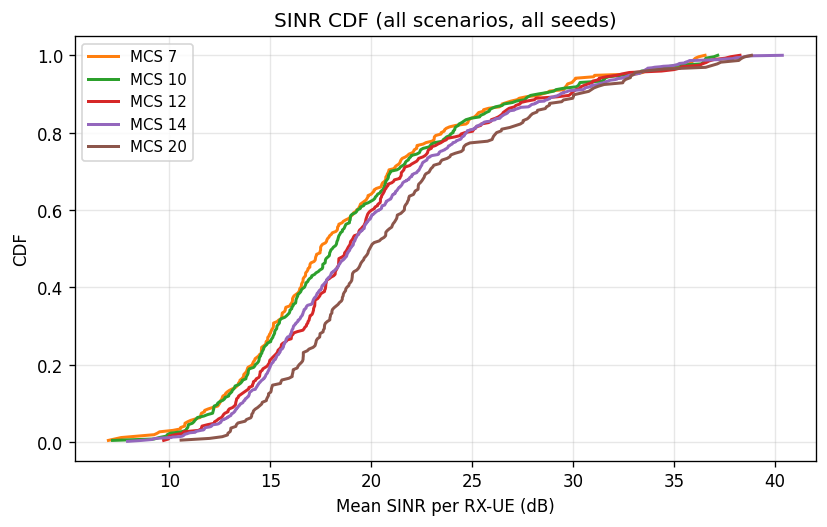

In [8]:
if not df_sinr.empty:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for mcs in mcs_vals:
        sub = df_sinr[df_sinr['mcs']==mcs]['mean_sinr_db'].dropna()
        if sub.empty: continue
        vals = np.sort(sub)
        cdf  = np.arange(1, len(vals)+1) / len(vals)
        ax.plot(vals, cdf, color=mcs_color(mcs), label=f'MCS {mcs}', lw=1.8)
    ax.set_xlabel('Mean SINR per RX-UE (dB)')
    ax.set_ylabel('CDF')
    ax.set_title('SINR CDF (all scenarios, all seeds)')
    ax.legend(fontsize=9); ax.grid(True, alpha=.3)
    plt.tight_layout()
    plt.show()
else:
    print('No SINR data')

## §8 Per-RX PRR heatmap (rx_node_id × MCS)

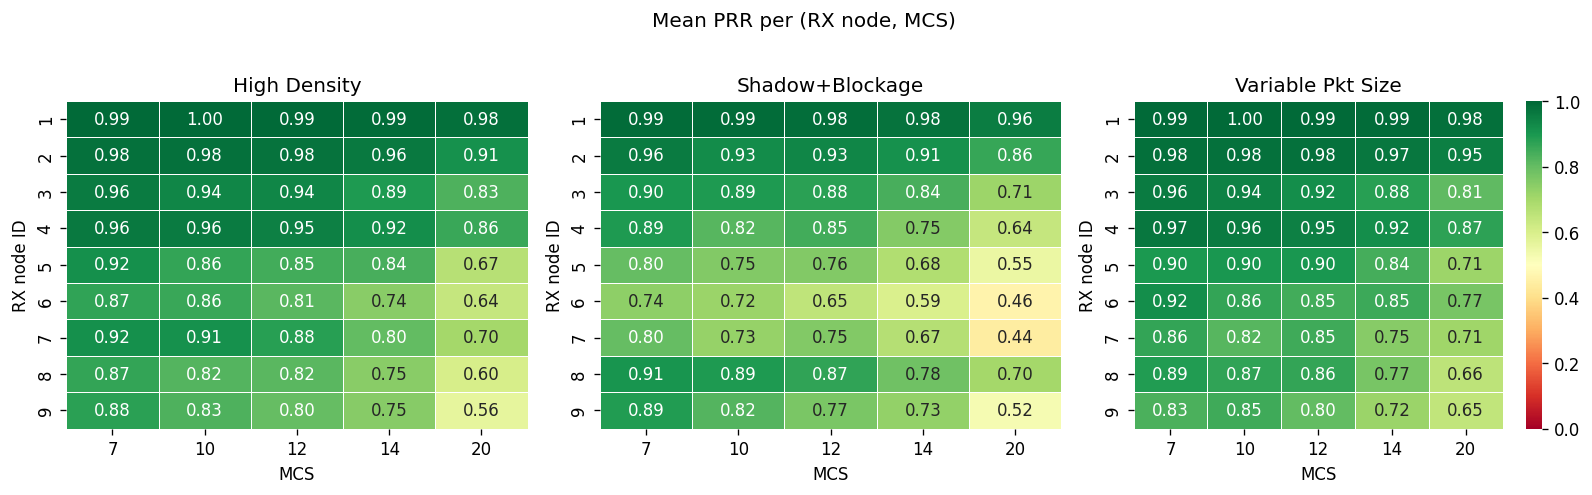

In [9]:
fig, axes = plt.subplots(1, len(scenarios), figsize=(4.5*len(scenarios), 4))
if len(scenarios)==1: axes=[axes]

for ax, scen in zip(axes, scenarios):
    sub = rx[rx['scenario']==scen]
    pivot = sub.groupby(['rx_node_id','mcs'])['prr'].mean().unstack('mcs')
    cols = [m for m in mcs_vals if m in pivot.columns]
    sns.heatmap(pivot[cols], ax=ax, vmin=0, vmax=1, cmap='RdYlGn',
                annot=True, fmt='.2f', linewidths=0.5, linecolor='white',
                cbar=(ax is axes[-1]))
    ax.set_title(slabel(scen))
    ax.set_xlabel('MCS'); ax.set_ylabel('RX node ID')
    ax.tick_params(axis='x', rotation=0)

fig.suptitle('Mean PRR per (RX node, MCS)', y=1.02)
plt.tight_layout()
plt.show()

## §9 Summary table & recommendation

For each (scenario, rx_node_id) pair, compute the MCS that maximises mean PRR
and the gain over MCS=14.

In [10]:
# Per-(scenario, rx_node, mcs) mean PRR
per_rx_mcs = (rx.groupby(['scenario','rx_node_id','mcs'])['prr']
                .mean().reset_index(name='mean_prr'))

# Best MCS per (scenario, rx_node_id)
best = (per_rx_mcs.loc[per_rx_mcs.groupby(['scenario','rx_node_id'])['mean_prr'].idxmax()]
                  .rename(columns={'mcs':'best_mcs','mean_prr':'prr_best'}))

# MCS=14 PRR
prr14 = (per_rx_mcs[per_rx_mcs['mcs']==14][['scenario','rx_node_id','mean_prr']]
                   .rename(columns={'mean_prr':'prr14'}))

summary = best.merge(prr14, on=['scenario','rx_node_id'], how='left')
summary['delta_pp'] = (summary['prr_best'] - summary['prr14']) * 100

# Also pull initial distance
dist_map = (rx.groupby(['scenario','rx_node_id'])['init_dist_m'].first().reset_index())
summary = summary.merge(dist_map, on=['scenario','rx_node_id'], how='left')

summary['action'] = summary.apply(
    lambda r: ('KEEP (MCS=14 is optimal)' if r['best_mcs']==14
               else f'→ MCS {int(r["best_mcs"])}  (+{r["delta_pp"]:.1f} pp)'),
    axis=1)

print('\n=== RECOMMENDATION TABLE ===')
print(summary[['scenario','rx_node_id','init_dist_m','prr14','prr_best','best_mcs','delta_pp','action']]
      .sort_values(['scenario','rx_node_id'])
      .to_string(index=False, float_format=lambda x: f'{x:.3f}'))


=== RECOMMENDATION TABLE ===
            scenario  rx_node_id  init_dist_m  prr14  prr_best  best_mcs  delta_pp               action
        high_density           1       12.500  0.989     0.995        10     0.588  → MCS 10  (+0.6 pp)
        high_density           2       25.000  0.963     0.979         7     1.585   → MCS 7  (+1.6 pp)
        high_density           3       37.500  0.891     0.958         7     6.669   → MCS 7  (+6.7 pp)
        high_density           4       50.000  0.918     0.963         7     4.487   → MCS 7  (+4.5 pp)
        high_density           5       62.500  0.837     0.916         7     7.955   → MCS 7  (+8.0 pp)
        high_density           6       75.000  0.743     0.870         7    12.687  → MCS 7  (+12.7 pp)
        high_density           7       87.500  0.802     0.916         7    11.481  → MCS 7  (+11.5 pp)
        high_density           8      100.000  0.745     0.865         7    11.996  → MCS 7  (+12.0 pp)
        high_density           9  

In [11]:
# Aggregate comparison table
print('\n=== MCS COMPARISON (from extract_mcs_sweep.py) ===')
cols_show = [c for c in ['scenario','mcs','prr_mean','prr_std','prr_worst_rx',
                          'pir_mean_ms','tput_mean_kbps','n_seeds'] if c in df_comp.columns]
print(df_comp[cols_show].sort_values(['scenario','mcs'])
      .to_string(index=False, float_format=lambda x: f'{x:.3f}'))


=== MCS COMPARISON (from extract_mcs_sweep.py) ===
            scenario  mcs  prr_mean  prr_std  prr_worst_rx  pir_mean_ms  tput_mean_kbps  n_seeds
        high_density    7     0.926    0.060         0.865       10.852         650.962       10
        high_density   10     0.906    0.081         0.823       11.145         636.735       10
        high_density   12     0.890    0.092         0.799       11.391         625.156       10
        high_density   14     0.849    0.118         0.743       12.081         596.584       30
        high_density   20     0.750    0.172         0.564       14.244         526.709       10
  shadowing_blockage    7     0.875    0.101         0.737       11.626         614.345       10
  shadowing_blockage   10     0.837    0.120         0.716       12.249         588.042       10
  shadowing_blockage   12     0.827    0.125         0.650       12.439         580.344       10
  shadowing_blockage   14     0.771    0.149         0.594       13.610    